In [2]:
%run ../Preprocessing/Preprocessing.ipynb

--------------PREPROCESSING:  ORIGINAL --------------


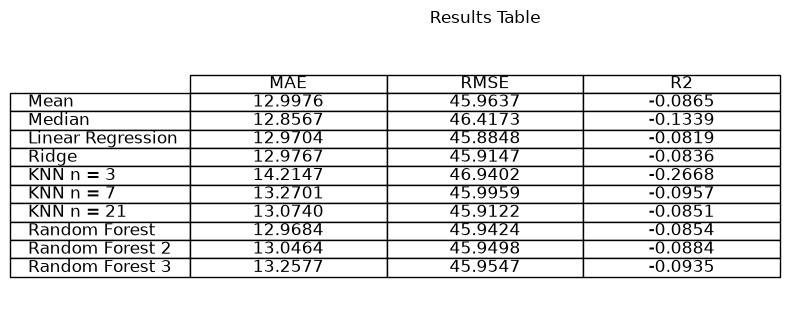

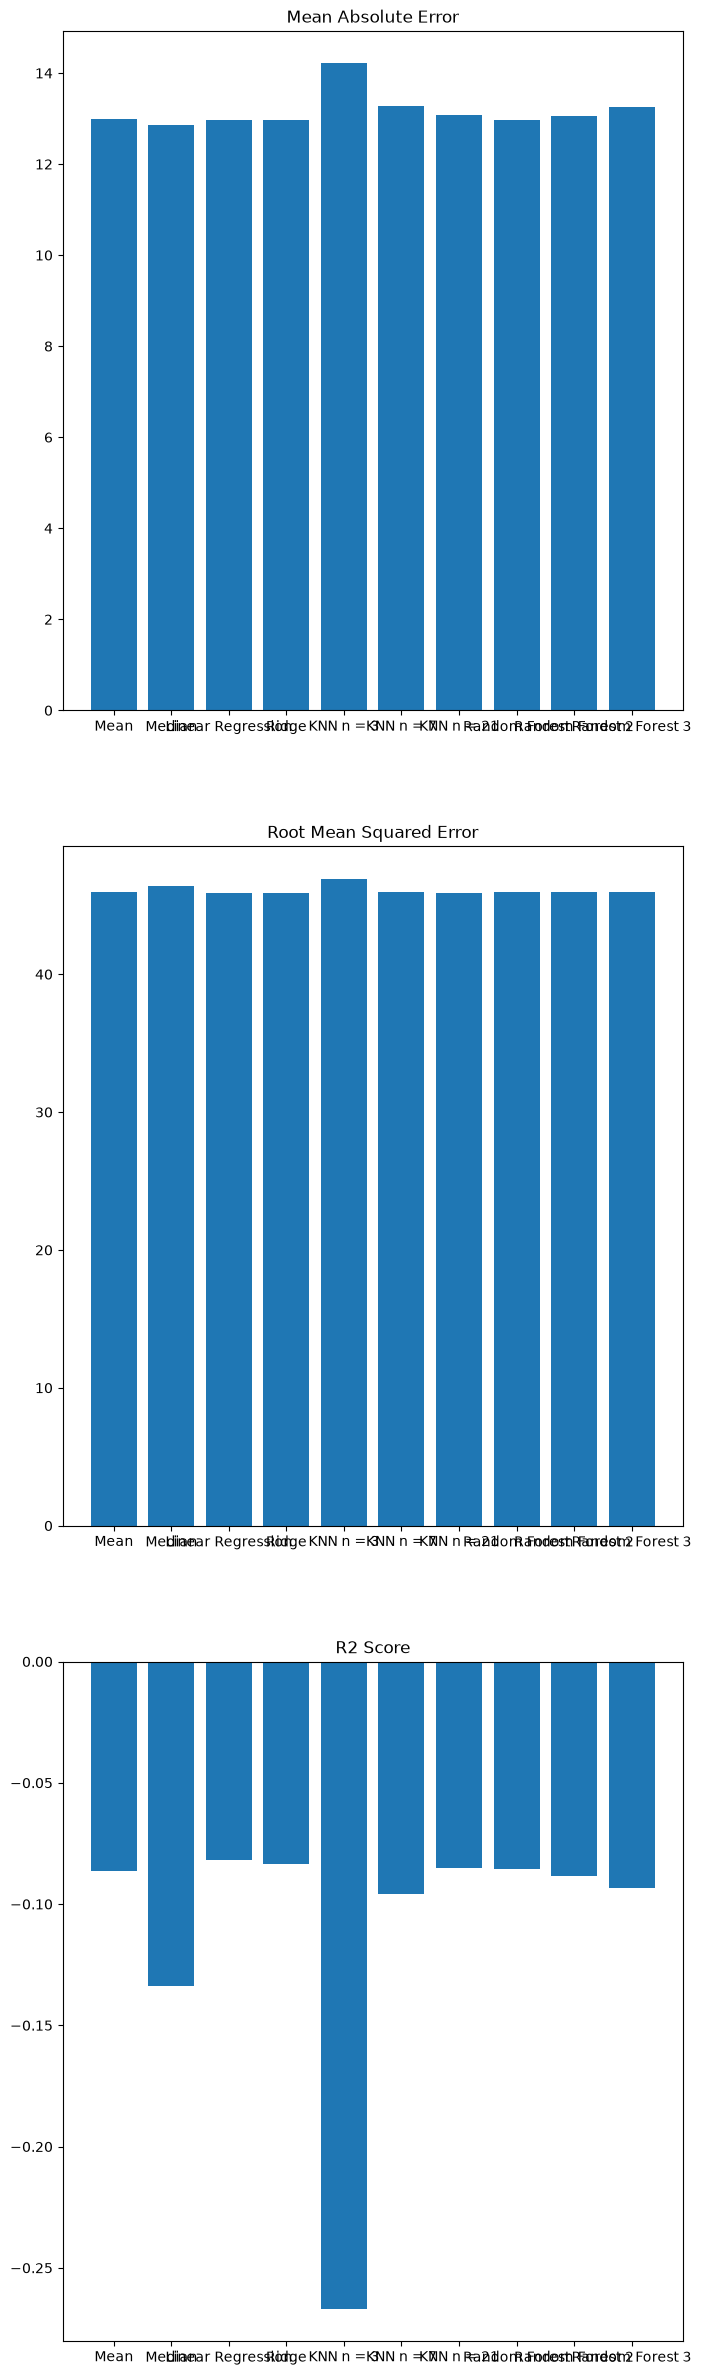

--------------PREPROCESSING:  ALL --------------


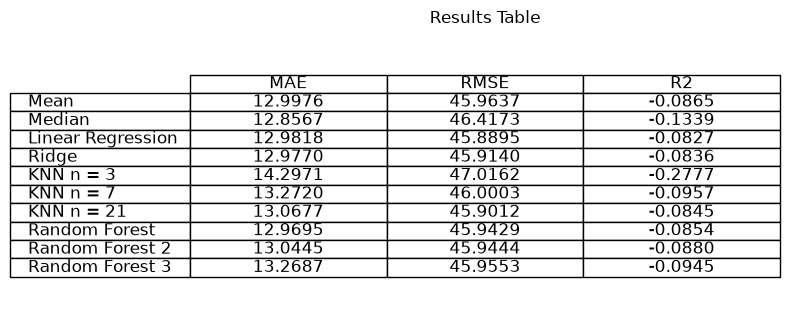

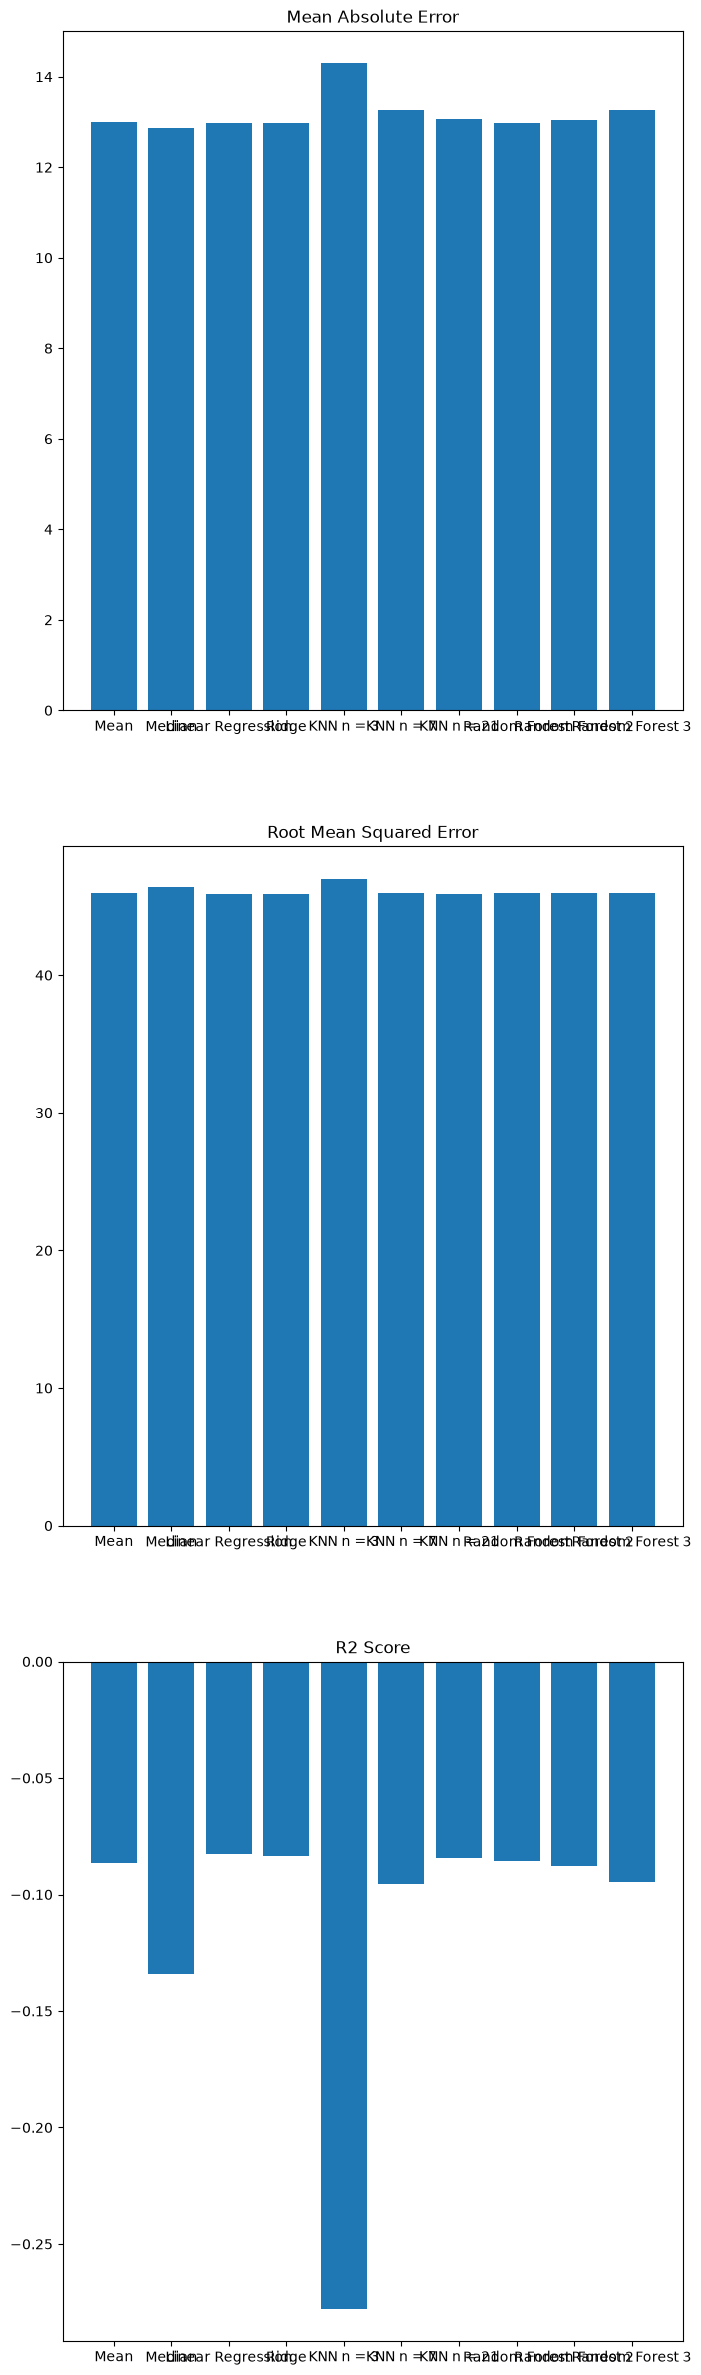

--------------PREPROCESSING:  FIRE WEATHER INDEX ONLY --------------


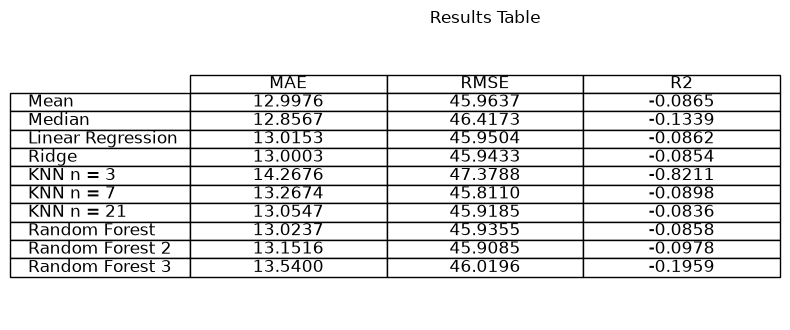

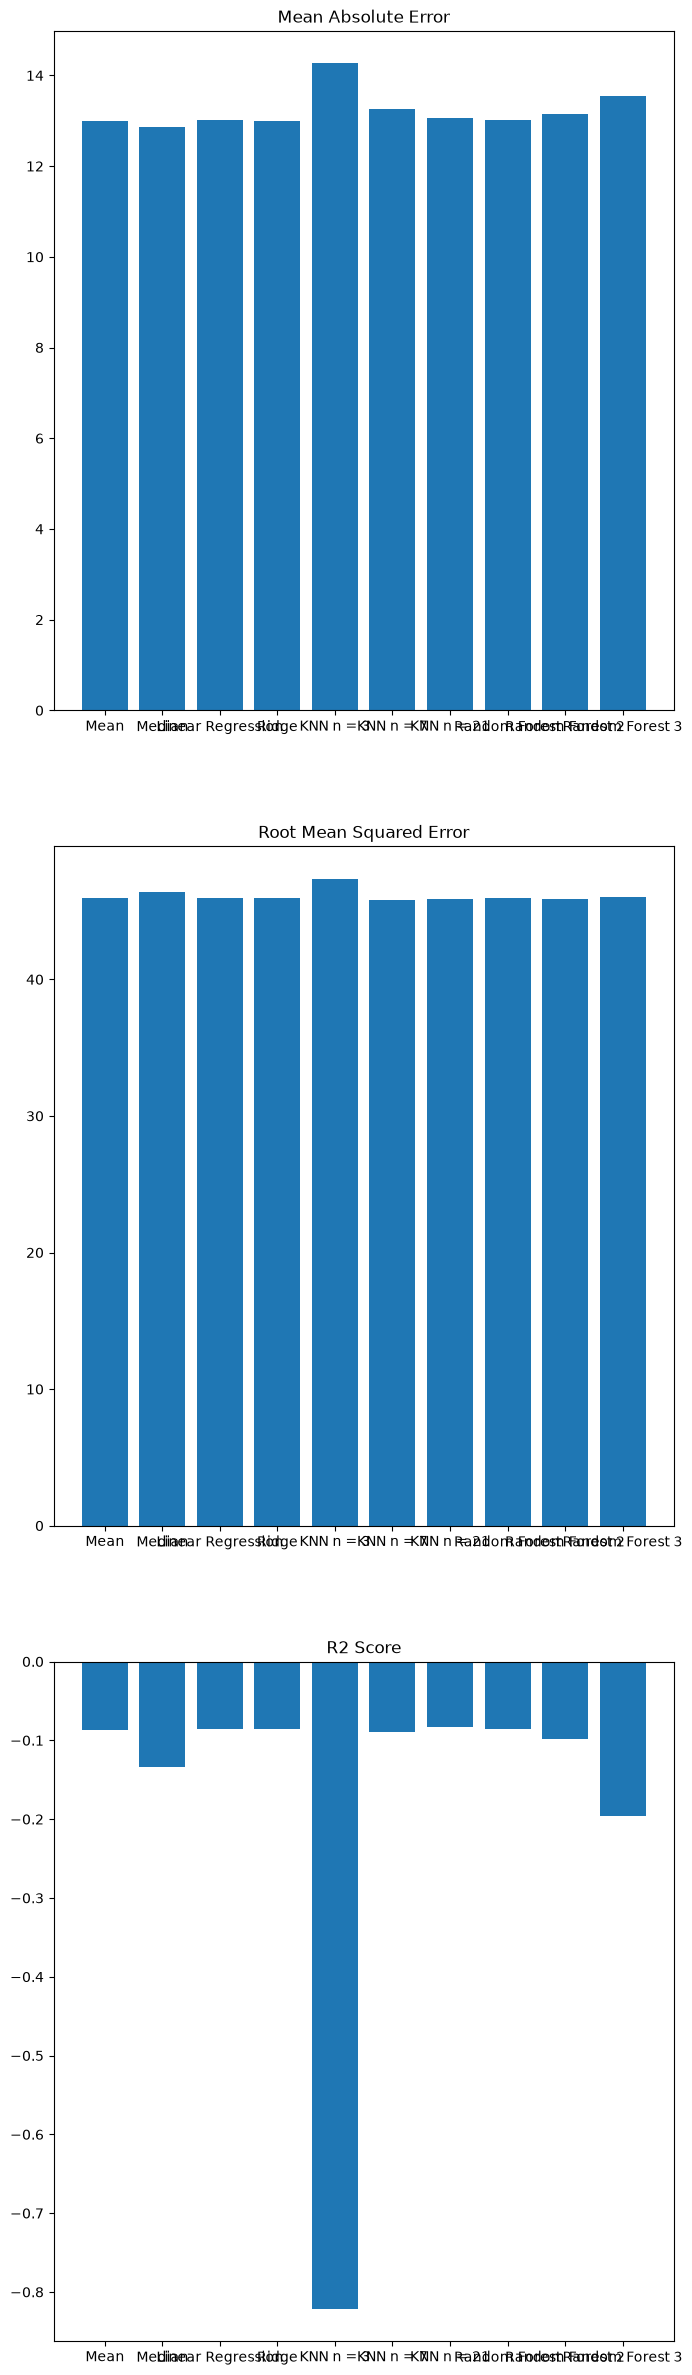

--------------PREPROCESSING:  VERY PRUNED (TEST) --------------


KeyboardInterrupt: 

In [ ]:
from sklearn.model_selection import cross_validate, RepeatedKFold
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.compose import TransformedTargetRegressor

#Split the data
X = df[categorical_columns + numerical_columns]
y = df["area"]

# Trying Different Models and preprocessing pipelines using cross validation

cv = RepeatedKFold(n_splits=10, n_repeats=10, random_state=RANDOM_STATE)

for title, preprocessing in preprocessing_pipelines.items():
    print("--------------PREPROCESSING: ", title,"--------------")

    resultsMAE =[]
    resultsRMSE = []
    resultsR2 = []
    #Run all of the models and print out their results
    for name, model in models.items():
        model = make_pipeline(
            preprocessing, 
            model
        )

        transformed_regressor = TransformedTargetRegressor(
            regressor=model, 
            func=np.log1p, 
            inverse_func=np.expm1)
        
        results = cross_validate(
            transformed_regressor, X, y, 
            cv=cv,
            scoring={"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2":"r2"},
            return_train_score=False
        )

        mae = -results["test_mae"].mean()
        rmse = -results["test_rmse"].mean()
        r2 = results["test_r2"].mean()
    
        resultsMAE.append(mae)
        resultsRMSE.append(rmse)
        resultsR2.append(r2)
    
        #print("Model: ", name ,"\nMean Absolute Error: ", mae, "\nRoot Mean Squared Error: ", rmse,"\nR2 Score: ", r2 ,"\n\n")

    #Plot Results
    model_names = list(models.keys())
    plt.figure(figsize={8,0.4 + len(model_names)*0.3})
    plt.axis("off")
    columns = ["MAE", "RMSE", "R2"]
    text = []
    for i in range(len(model_names)):
        text.append([f"{resultsMAE[i]:.4f}",f"{resultsRMSE[i]:.4f}",f"{resultsR2[i]:.4f}"])
    
    table = plt.table(
        cellText = text,
        rowLabels = model_names,
        colLabels = columns,
        loc="center",
        cellLoc="center"
    )
    table.auto_set_font_size(False)
    table.set_fontsize(12)
    plt.title(f"Results Table:  {title}")
    plt.tight_layout()
    plt.show
    
    plt.figure(figsize={8,len(model_names) * 3}) ##Figure is dynamically sized to allow for more models to be added as needed


    plt.subplot(311, title="Mean Absolute Error").bar(range(len(resultsMAE)),resultsMAE)
    plt.xticks(range(len(model_names)),model_names)
    
    plt.subplot(312, title="Root Mean Squared Error").bar(range(len(resultsRMSE)),resultsRMSE)
    plt.xticks(range(len(model_names)),model_names)
    
    plt.subplot(313, title="R2 Score").bar(range(len(resultsR2)),resultsR2)
    plt.xticks(range(len(model_names)),model_names)

    plt.show()